## 1. Lade den Datensatz und erste Exploration:

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Matplotlib Inline für Jupyter Notebooks
%matplotlib inline

# Laden des Amazon UK Produktdatensatzes
df = pd.read_csv("Raw-Data.csv/amz_uk_price_prediction_dataset.csv")



In [24]:
df = pd.read_csv("/Users/mishka/Documents/GitHub/lab-eda-univariate/Raw-Data.csv/amz_uk_price_prediction_dataset.csv")

## 2.Produktkategorien analysieren:

In [8]:

print(df.head())


   uid        asin                                              title  stars  \
0    1  B09B96TG33  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
1    2  B01HTH3C8S  Anker Soundcore mini, Super-Portable Bluetooth...    4.7   
2    3  B09B8YWXDF  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
3    4  B09B8T5VGV  Echo Dot with clock (5th generation, 2022 rele...    4.7   
4    5  B09WX6QD65  Introducing Echo Pop | Full sound compact Wi-F...    4.6   

   reviews  price  isBestSeller  boughtInLastMonth        category  
0    15308  21.99         False                  0  Hi-Fi Speakers  
1    98099  23.99          True                  0  Hi-Fi Speakers  
2    15308  21.99         False                  0  Hi-Fi Speakers  
3     7205  31.99         False                  0  Hi-Fi Speakers  
4     1881  17.99         False                  0  Hi-Fi Speakers  


In [9]:
print(df.dtypes)

uid                    int64
asin                  object
title                 object
stars                float64
reviews                int64
price                float64
isBestSeller            bool
boughtInLastMonth      int64
category              object
dtype: object


In [10]:
print(df.shape)


(2443651, 9)


In [11]:
# Häufigkeitstabelle für die Produktkategorien
frequency_table = df['category'].value_counts()
print(frequency_table)



category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64


In [12]:
# Top 5 am häufigsten gelisteten Produktkategorien
top_5_categories = frequency_table.head(5)
print(top_5_categories)



category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64


/var/folders/f6/2h1ph12j6r9c8gpllh_52j940000gn/T/ipykernel_4575/341484301.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=frequency_table.index, y=frequency_table.values, palette="viridis")


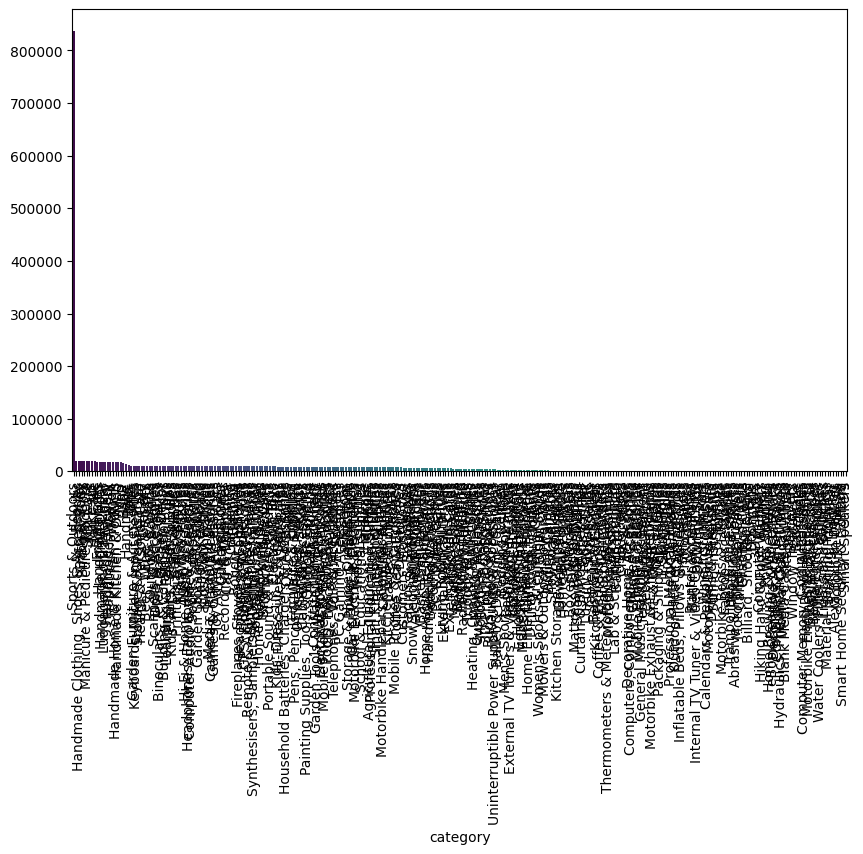

In [13]:
# Balkendiagramm für alle Kategorien
plt.figure(figsize=(10, 6))
sns.barplot(x=frequency_table.index, y=frequency_table.values, palette="viridis")
plt.xticks(rotation=90)
plt.show()


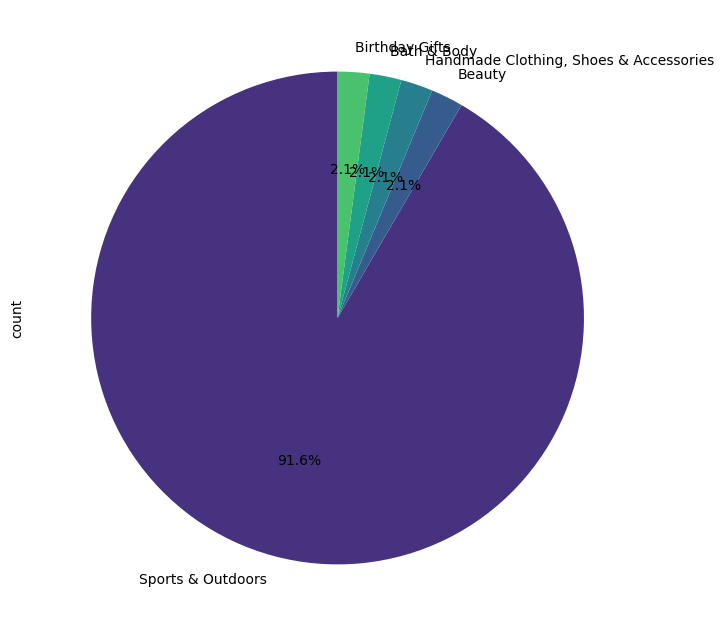

In [14]:
# Kreisdiagramm für die Top 5 Kategorien
plt.figure(figsize=(8, 8))
top_5_categories.plot.pie(autopct='%1.1f%%', startangle=90, colors=sns.color_palette("viridis"))
plt.show()


## Produktpreise analysieren

In [15]:
# Maßzahlen der zentralen Tendenz
mean_price = df['price'].mean()
median_price = df['price'].median()
mode_price = df['price'].mode()[0]
print("Mean:", mean_price, "Median:", median_price, "Mode:", mode_price)

Mean: 89.24380943923663 Median: 19.09 Mode: 9.99


In [16]:
# Maßzahlen der Streuung
variance_price = df['price'].var()
std_dev_price = df['price'].std()
min_price = df['price'].min()
max_price = df['price'].max()
range_price = max_price - min_price
iqr_price = df['price'].quantile(0.75) - df['price'].quantile(0.25)
print("Variance:", variance_price, "Standard Deviation:", std_dev_price, "Range:", range_price, "IQR:", iqr_price)

Variance: 119445.48532256528 Standard Deviation: 345.60886175352226 Range: 100000.0 IQR: 36.0


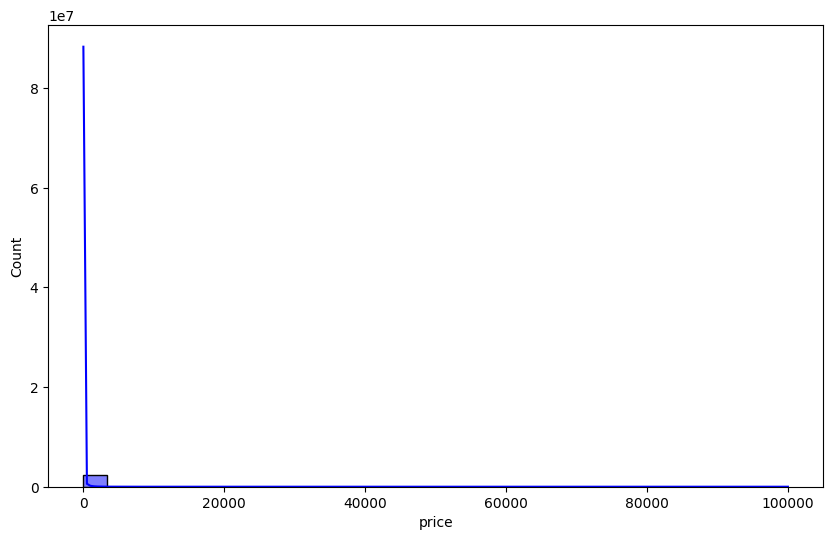

In [17]:
# Histogramm der Produktpreise
plt.figure(figsize=(10, 6))
sns.histplot(df['price'], kde=True, bins=30, color="blue")
plt.show()


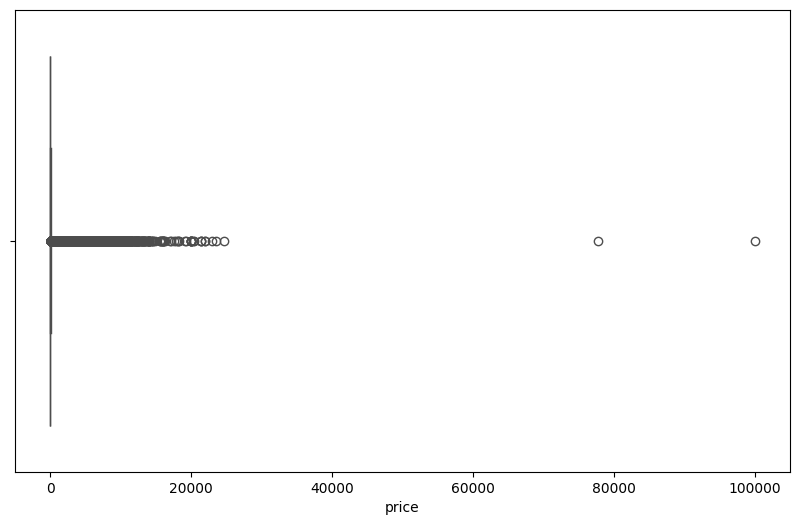

In [18]:
# Boxplot der Produktpreise
plt.figure(figsize=(10, 6))
sns.boxplot(x=df['price'], color="blue")
plt.show()

 ## Produktbewertungen analysieren

Mittelwert (mean) berechnen:

In [26]:
mean_stars = df['stars'].mean()



Median berechnen:

In [27]:
median_stars = df['stars'].median()

Modus berechnen:

In [28]:
mode_stars = df['stars'].mode()[0]


Ergebnisse:

In [29]:
print("Mean:", mean_stars, "Median:", median_stars, "Mode:", mode_stars)

Mean: 2.152836472966065 Median: 0.0 Mode: 0.0


In [23]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

Visualisierung der Verteilung der Bewertungen:

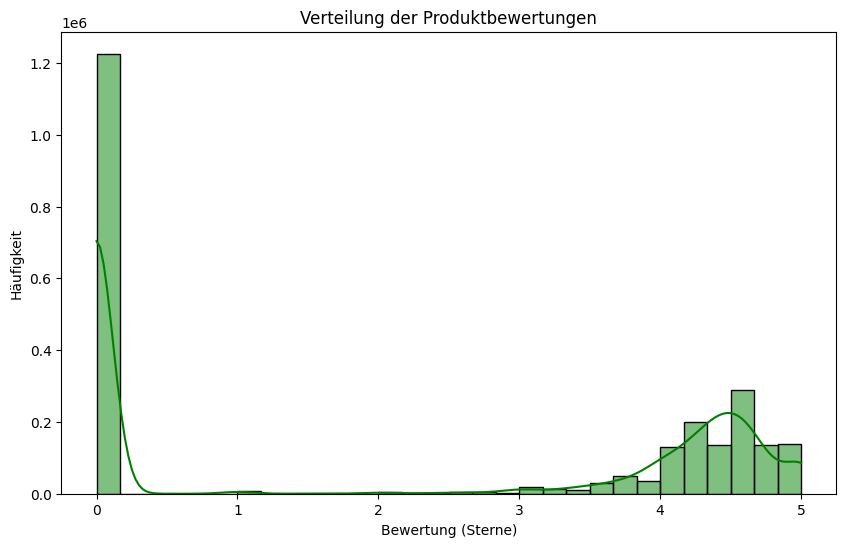

In [30]:
plt.figure(figsize=(10, 6))
sns.histplot(df['stars'], kde=True, bins=30, color="green")
plt.title('Verteilung der Produktbewertungen')
plt.xlabel('Bewertung (Sterne)')
plt.ylabel('Häufigkeit')
plt.show()
